# Blood Type Distribution – Pandas Analysis (cleaned)

## 1. Load the dataset
`keep_default_na=False` is important: the continent code **NA** (North America) would otherwise be read as a missing value.

In [1]:
import pandas as pd

df = pd.read_csv("blood_type_distribution.csv", keep_default_na=False, na_values=[""])

## 2. Basic inspection

In [2]:
df.head()

,Country,Population,O+,A+,B+,AB+,O-,A-,B-,AB-,Continent
0,Albania,3107100,34.10,31.20,14.5,5.20,6.00,5.50,2.60,0.90,EU
1,Algeria,47022473,40.00,30.00,15.0,4.25,6.60,2.30,1.10,0.75,AF
2,Argentina,46994384,50.34,31.09,8.2,2.16,4.29,2.98,0.74,0.20,SA
3,Armenia,2976765,29.00,46.30,12.0,5.60,2.00,3.70,1.00,0.40,AS
4,Australia,26768598,38.00,32.00,12.0,4.00,7.00,6.00,2.00,1.00,OC


In [3]:
df.shape

(127, 11)

In [4]:
df.columns.tolist()

['Country',
 'Population',
 'O+',
 'A+',
 'B+',
 'AB+',
 'O-',
 'A-',
 'B-',
 'AB-',
 'Continent']

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 127 entries, 0 to 126
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Country     127 non-null    str    
 1   Population  127 non-null    int64  
 2   O+          127 non-null    float64
 3   A+          127 non-null    float64
 4   B+          127 non-null    float64
 5   AB+         127 non-null    float64
 6   O-          126 non-null    float64
 7   A-          126 non-null    float64
 8   B-          126 non-null    float64
 9   AB-         124 non-null    float64
 10  Continent   126 non-null    str    
dtypes: float64(8), int64(1), str(2)
memory usage: 12.3 KB


## 3. Missing values and duplicates

In [6]:
df.isnull().sum()

Country       0
Population    0
O+            0
A+            0
B+            0
AB+           0
O-            1
A-            1
B-            1
AB-           3
Continent     1
dtype: int64

In [7]:
df[df.isnull().any(axis=1)]

,Country,Population,O+,A+,B+,AB+,O-,A-,B-,AB-,Continent
31,Egypt,111247248,36.44,33.94,20.96,8.65,NaN,NaN,NaN,NaN,AF
81,New Zealand,5161211,38.00,32.00,10.00,3.00,9.0,6.0,1.0,NaN,OC
87,Oman,3901992,44.90,17.40,20.20,6.80,7.4,0.6,2.7,NaN,AS
126,World,8057236243,38.40,27.30,8.10,2.00,13.1,8.1,2.0,0.01,NaN


In [8]:
df.duplicated().sum()

np.int64(0)

## 4. Clean the data

**4a. Continent:** only the `World` row has no continent (it is a global total, not a country). Remove it so it does not distort rankings and averages.

In [9]:
df = df[df['Country'] != 'World'].reset_index(drop=True)
df['Continent'].isnull().sum()

np.int64(0)

**4b. Missing negative blood types:** each row should add up to about 100%. Instead of filling with the column mean, fill the missing cells with the remaining percentage (100 − known values), split equally among the missing cells.

In [10]:
blood_cols = ['O+', 'A+', 'B+', 'AB+', 'O-', 'A-', 'B-', 'AB-']
neg_cols = ['O-', 'A-', 'B-', 'AB-']

for i in df.index[df[neg_cols].isnull().any(axis=1)]:
    missing = [c for c in neg_cols if pd.isnull(df.loc[i, c])]
    remaining = max(0, 100 - df.loc[i, blood_cols].sum())
    df.loc[i, missing] = remaining / len(missing)

df[blood_cols + ['Continent']].isnull().sum()

O+           0
A+           0
B+           0
AB+          0
O-           0
A-           0
B-           0
AB-          0
Continent    0
dtype: int64

In [11]:
df.loc[df['Country'].isin(['Egypt', 'New Zealand', 'Oman']), ['Country'] + blood_cols]

,Country,O+,A+,B+,AB+,O-,A-,B-,AB-
31,Egypt,36.44,33.94,20.96,8.65,0.0025,0.0025,0.0025,0.0025
81,New Zealand,38.00,32.00,10.00,3.00,9.0000,6.0000,1.0000,1.0000
87,Oman,44.90,17.40,20.20,6.80,7.4000,0.6000,2.7000,0.0000


## 5. Describe the data

In [12]:
df.describe()

,Population,O+,A+,B+,AB+,O-,A-,B-,AB-
count,1.260000e+02,126.000000,126.000000,126.000000,126.000000,126.000000,126.000000,126.000000,126.000000
mean,5.969492e+07,40.440397,29.168333,16.352460,4.701190,4.022401,3.298353,1.344544,0.474067
std,1.821279e+08,9.912451,6.611463,7.504513,2.255029,2.570702,2.564671,0.874102,0.379525
min,4.027200e+04,27.000000,14.000000,4.720000,0.500000,0.002500,0.002500,0.002500,0.000000
25%,5.523212e+06,32.655000,24.120000,10.000000,2.900000,1.800000,1.000000,0.600000,0.110000
50%,1.266462e+07,38.000000,30.000000,15.100000,4.270000,4.255000,2.700000,1.275000,0.400000
75%,4.701545e+07,46.775000,34.000000,21.045000,6.300000,6.000000,6.000000,2.000000,0.900000
max,1.416043e+09,75.000000,46.300000,36.800000,11.320000,13.300000,9.000000,3.130000,1.200000


## 6. Create new columns

In [13]:
df['Total_Positive'] = df[['O+', 'A+', 'B+', 'AB+']].sum(axis=1)
df['Total_Negative'] = df[['O-', 'A-', 'B-', 'AB-']].sum(axis=1)
df['Positive_Minus_Negative'] = df['Total_Positive'] - df['Total_Negative']
df['Total_Percent'] = df[blood_cols].sum(axis=1)

df[['Country', 'Total_Positive', 'Total_Negative', 'Positive_Minus_Negative']].head()

,Country,Total_Positive,Total_Negative,Positive_Minus_Negative
0,Albania,85.00,15.00,70.00
1,Algeria,89.25,10.75,78.50
2,Argentina,91.79,8.21,83.58
3,Armenia,92.90,7.10,85.80
4,Australia,86.00,16.00,70.00


**Data quality check:** rows whose percentages do not add up to ~100 (source data issue, left unchanged).

In [14]:
df.loc[(df['Total_Percent'] - 100).abs() > 1, ['Country', 'Total_Percent']].sort_values('Total_Percent')

,Country,Total_Percent
12,Bolivia,91.0
64,Libya,92.0
98,Saudi Arabia,93.0
7,Bahrain,96.0
119,United Kingdom,96.0
44,Honduras,98.0
45,Hong Kong,101.1
79,Nepal,102.0
4,Australia,102.0
89,Papua New Guinea,102.2


## 7. Countries with the highest / lowest positive and negative percentages

In [15]:
print("Highest positive:", df.loc[df['Total_Positive'].idxmax(), ['Country', 'Total_Positive']].tolist())
print("Lowest positive :", df.loc[df['Total_Positive'].idxmin(), ['Country', 'Total_Positive']].tolist())
print("Highest negative:", df.loc[df['Total_Negative'].idxmax(), ['Country', 'Total_Negative']].tolist())
print("Lowest negative :", df.loc[df['Total_Negative'].idxmin(), ['Country', 'Total_Negative']].tolist())

Highest positive: ['Nepal', np.float64(101.19999999999999)]
Lowest positive : ['United Kingdom', np.float64(76.0)]
Highest negative: ['Mongolia', np.float64(23.310000000000002)]
Lowest negative : ['Egypt', np.float64(0.010000000000005116)]


In [16]:
df.nlargest(5, 'Total_Positive')[['Country', 'Total_Positive']]

,Country,Total_Positive
79,Nepal,101.20
45,Hong Kong,100.00
105,South Korea,100.00
31,Egypt,99.99
11,Bhutan,99.87


In [17]:
df.nlargest(5, 'Total_Negative')[['Country', 'Total_Negative']]

,Country,Total_Negative
75,Mongolia,23.31
119,United Kingdom,20.00
14,Brazil,19.50
106,Spain,18.50
102,Slovenia,18.00


## 8. Averages

In [18]:
print("Mean Total_Positive:", round(df['Total_Positive'].mean(), 2))
print("Mean Total_Negative:", round(df['Total_Negative'].mean(), 2))

Mean Total_Positive: 90.66
Mean Total_Negative: 9.14


In [19]:
df[blood_cols].mean().round(2).sort_values(ascending=False)

O+     40.44
A+     29.17
B+     16.35
AB+     4.70
O-      4.02
A-      3.30
B-      1.34
AB-     0.47
dtype: float64

In [20]:
df[blood_cols].mean().idxmax()

'O+'

## 9. Continent analysis

In [21]:
df['Continent'].value_counts()

Continent
AS    41
EU    39
AF    23
NA    10
SA     9
OC     4
Name: count, dtype: int64

In [22]:
df.groupby('Continent')['Population'].sum().sort_values(ascending=False)

Continent
AS    4660492109
AF    1077837482
EU     738804989
NA     564204169
SA     437293967
OC      42927653
Name: Population, dtype: int64

In [23]:
print("Highest mean Total_Positive:", df.groupby('Continent')['Total_Positive'].mean().idxmax())
print("Highest mean Total_Negative:", df.groupby('Continent')['Total_Negative'].mean().idxmax())
print("Highest mean O+            :", df.groupby('Continent')['O+'].mean().idxmax())
print("Highest mean A+            :", df.groupby('Continent')['A+'].mean().idxmax())

Highest mean Total_Positive: AS
Highest mean Total_Negative: EU
Highest mean O+            : SA
Highest mean A+            : EU


In [24]:
pivot = df.pivot_table(index='Continent', values=blood_cols, aggfunc='mean')[blood_cols].round(2)
pivot

,O+,A+,B+,AB+,O-,A-,B-,AB-
Continent,,,,,,,,
AF,46.08,24.78,18.37,4.05,3.30,1.65,1.10,0.33
AS,37.17,27.62,23.06,6.42,2.49,1.76,1.07,0.28
EU,33.48,34.68,11.89,4.68,6.01,6.20,2.08,0.86
NA,51.08,27.43,11.39,2.50,3.52,2.60,0.96,0.31
OC,43.68,32.38,12.02,3.48,4.70,3.30,0.92,0.57
SA,57.84,24.07,7.43,1.61,4.52,2.69,0.67,0.17


## 10. Population analysis

In [25]:
df.nlargest(5, 'Population')[['Country', 'Population']]

,Country,Population
95,People's Republic of China,1416043270
48,India,1409128296
120,United States,341963408
49,Indonesia,281562465
88,Pakistan,252363571


In [26]:
df.nsmallest(5, 'Population')[['Country', 'Population']]

,Country,Population
65,Liechtenstein,40272
47,Iceland,364036
70,Malta,469730
68,Macao,644426
67,Luxembourg,671254


## 11. Filtering: population above 50 million and Total_Positive above 80

In [27]:
high_pop_positive = df[(df['Population'] > 50_000_000) & (df['Total_Positive'] > 80)]
high_pop_positive[['Country', 'Population', 'Total_Positive']]

,Country,Population,Total_Positive
8,Bangladesh,168697184,98.22
14,Brazil,220051512,80.50
27,Democratic Republic of the Congo,115403027,98.40
31,Egypt,111247248,99.99
34,Ethiopia,118550298,93.00
37,France,68374591,84.90
40,Germany,84119100,85.00
48,India,1409128296,94.13
49,Indonesia,281562465,99.50
50,Iran,88386937,89.70


## 12. Final check and save

In [28]:
print(df.shape)
print(df.isnull().sum().sum(), "missing values")
df.to_csv("blood_type_distribution_cleaned.csv", index=False)

(126, 15)
0 missing values


In [29]:
import matplotlib.pyplot as plt

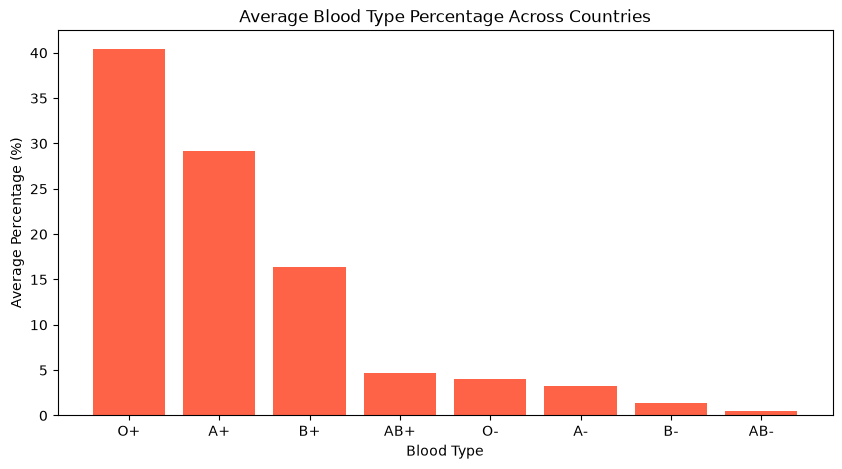

In [30]:
avg = df[blood_cols].mean().sort_values(ascending=False)
plt.figure(figsize=(10,5))
plt.bar(avg.index, avg.values, color = 'tomato')
plt.title('Average Blood Type Percentage Across Countries')
plt.xlabel('Blood Type')
plt.ylabel('Average Percentage (%)')
plt.show()

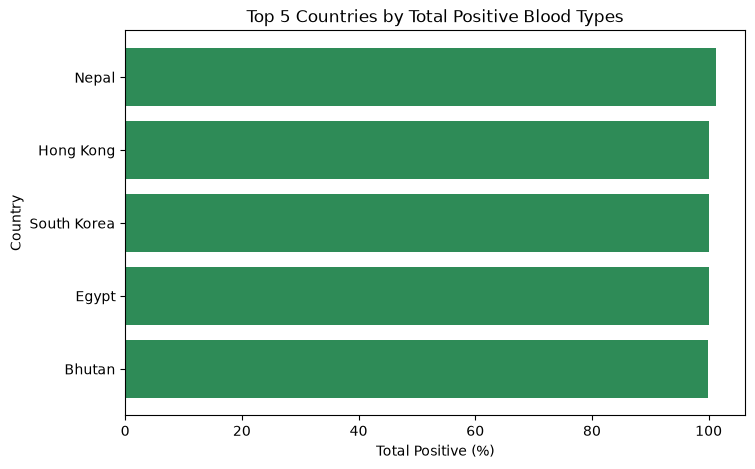

In [31]:
top5_pos = df.nlargest(5,'Total_Positive')
plt.figure(figsize=(8, 5))
plt.barh(top5_pos['Country'], top5_pos['Total_Positive'], color='seagreen')
plt.title('Top 5 Countries by Total Positive Blood Types')
plt.xlabel('Total Positive (%)')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.show()

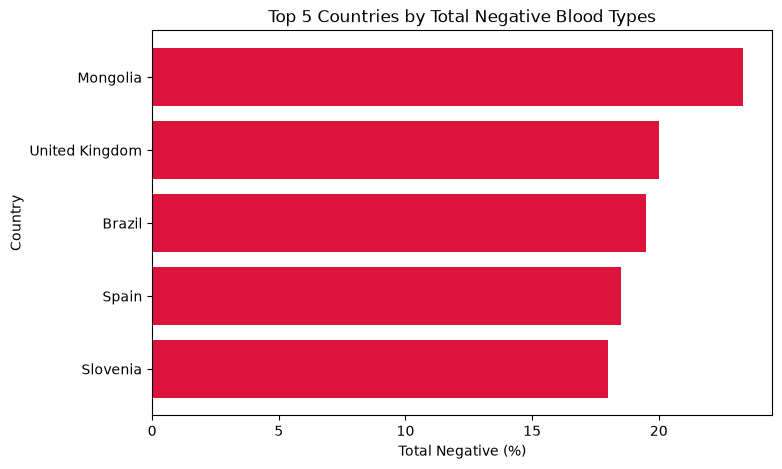

In [32]:
top5_neg = df.nlargest(5, 'Total_Negative')
plt.figure(figsize=(8, 5))
plt.barh(top5_neg['Country'], top5_neg['Total_Negative'], color='crimson')
plt.title('Top 5 Countries by Total Negative Blood Types')
plt.xlabel('Total Negative (%)')
plt.ylabel('Country')
plt.gca().invert_yaxis()
plt.show()

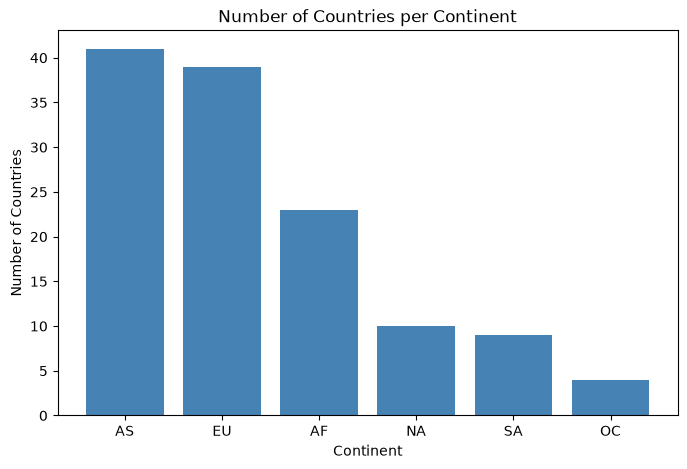

In [33]:
continent_counts = df['Continent'].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(continent_counts.index, continent_counts.values, color='steelblue')
plt.title('Number of Countries per Continent')
plt.xlabel('Continent')
plt.ylabel('Number of Countries')
plt.show()

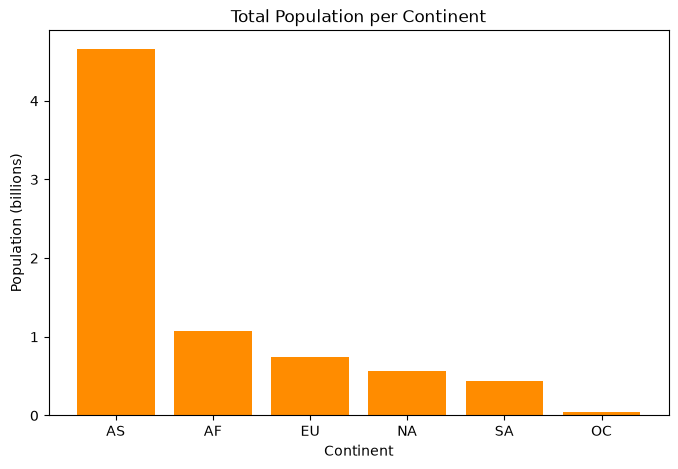

In [34]:
continent_pop = df.groupby('Continent')['Population'].sum().sort_values(ascending = False)
plt.figure(figsize=(8, 5))
plt.bar(continent_pop.index, continent_pop.values / 1e9, color='darkorange')
plt.title('Total Population per Continent')
plt.xlabel('Continent')
plt.ylabel('Population (billions)')
plt.show()

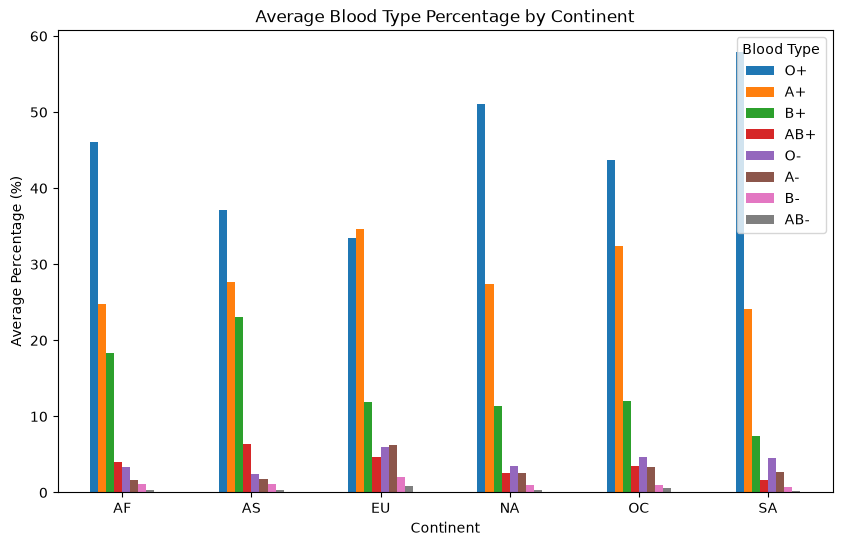

In [35]:
pivot.plot(kind='bar', figsize=(10, 6))
plt.title('Average Blood Type Percentage by Continent')
plt.xlabel('Continent')
plt.ylabel('Average Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Blood Type')
plt.show()

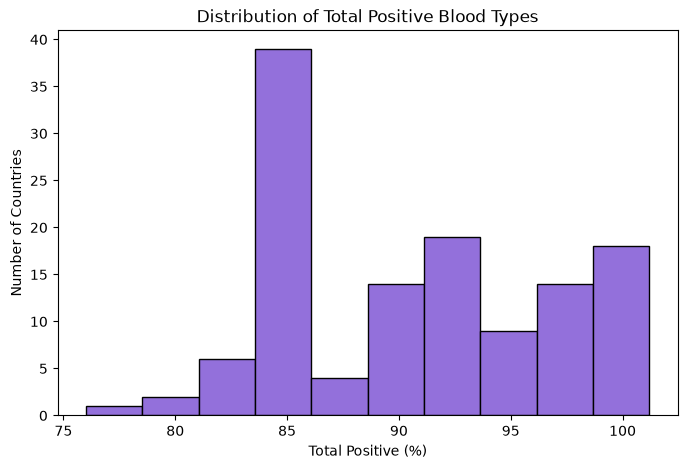

In [36]:
plt.figure(figsize=(8, 5))
plt.hist(df['Total_Positive'], bins=10, color='mediumpurple', edgecolor='black')
plt.title('Distribution of Total Positive Blood Types')
plt.xlabel('Total Positive (%)')
plt.ylabel('Number of Countries')
plt.show()

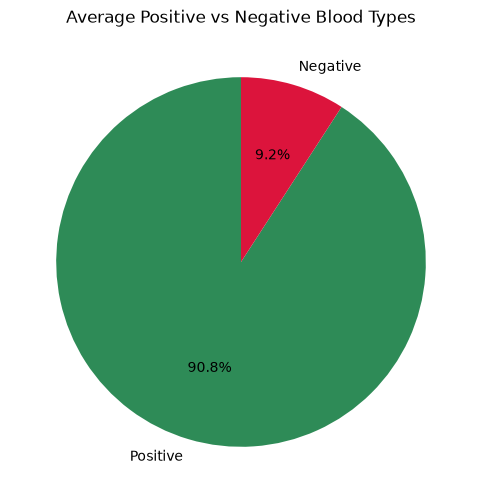

In [37]:
avg_share = [df['Total_Positive'].mean(), df['Total_Negative'].mean()]

plt.figure(figsize=(6, 6))
plt.pie(avg_share, labels=['Positive', 'Negative'], autopct='%1.1f%%',
        colors=['seagreen', 'crimson'], startangle=90)
plt.title('Average Positive vs Negative Blood Types')
plt.show()

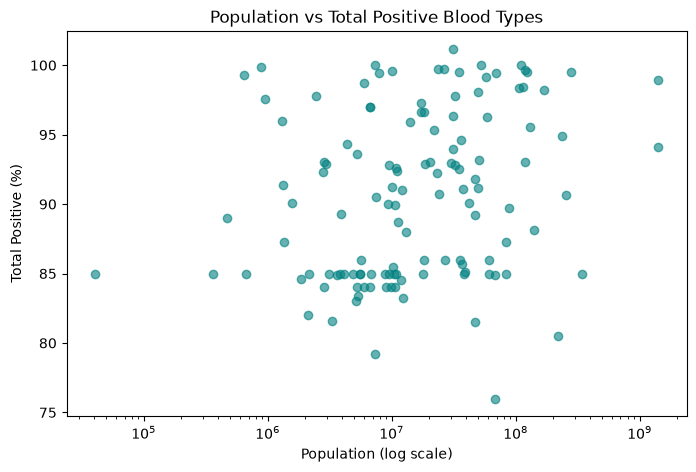

In [38]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Population'], df['Total_Positive'], color='teal', alpha=0.6)
plt.xscale('log')
plt.title('Population vs Total Positive Blood Types')
plt.xlabel('Population (log scale)')
plt.ylabel('Total Positive (%)')
plt.show()

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

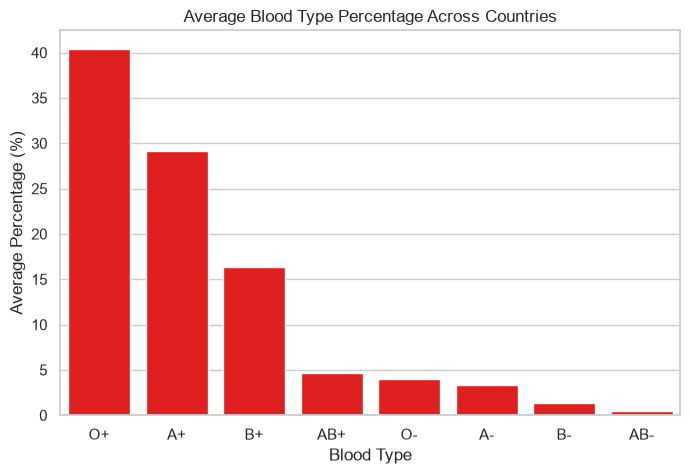

In [42]:
avg = df[blood_cols].mean().sort_values(ascending = False)
plt.figure(figsize=(8,5))
sns.barplot(x=avg.index, y=avg.values, color = 'red')
plt.title('Average Blood Type Percentage Across Countries')
plt.xlabel('Blood Type')
plt.ylabel('Average Percentage (%)')
plt.show()

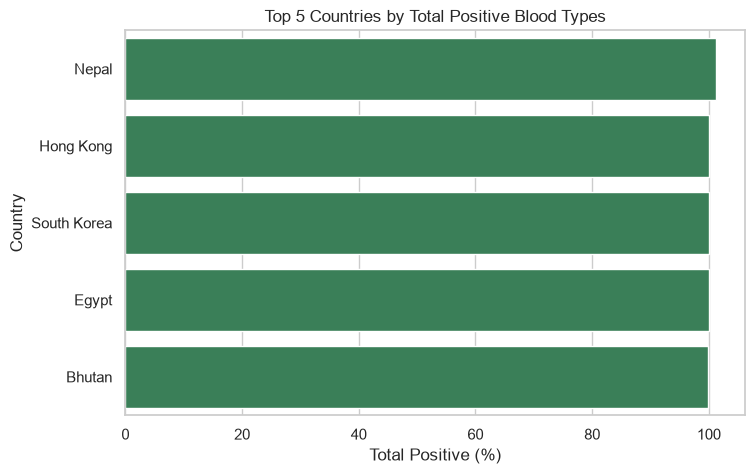

In [45]:
top5_pos = df.nlargest(5, 'Total_Positive')
plt.figure(figsize=(8, 5))
sns.barplot(data=top5_pos, x='Total_Positive', y='Country', color='seagreen')
plt.title('Top 5 Countries by Total Positive Blood Types')
plt.xlabel('Total Positive (%)')
plt.ylabel('Country')
plt.show()

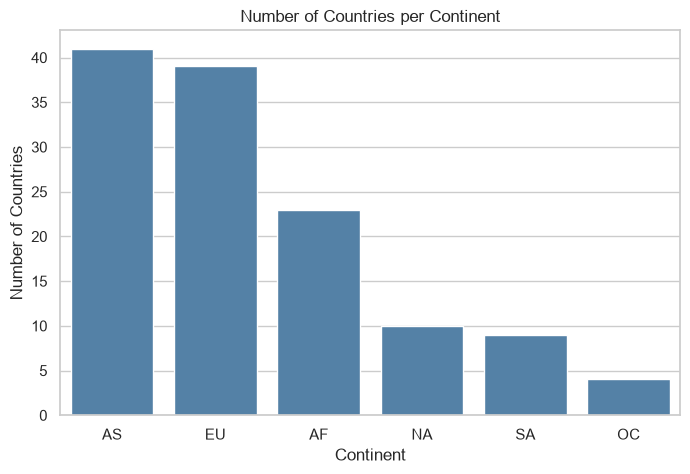

In [48]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Continent', order=df['Continent'].value_counts().index, color='steelblue')
plt.title('Number of Countries per Continent')
plt.xlabel('Continent')
plt.ylabel('Number of Countries')
plt.show()

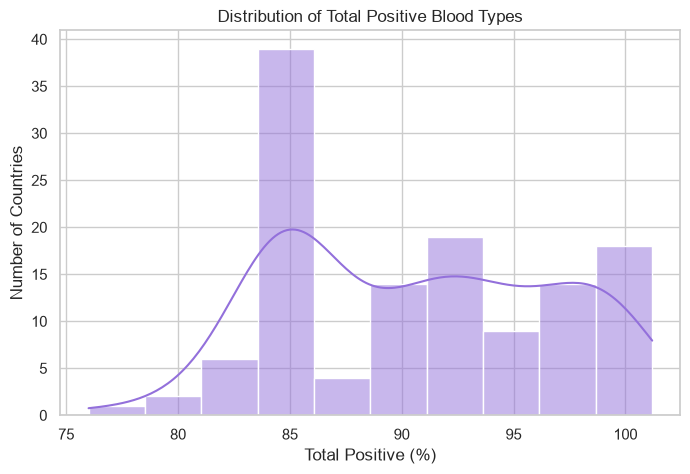

In [49]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Total_Positive', bins=10, kde=True, color='mediumpurple')
plt.title('Distribution of Total Positive Blood Types')
plt.xlabel('Total Positive (%)')
plt.ylabel('Number of Countries')
plt.show()

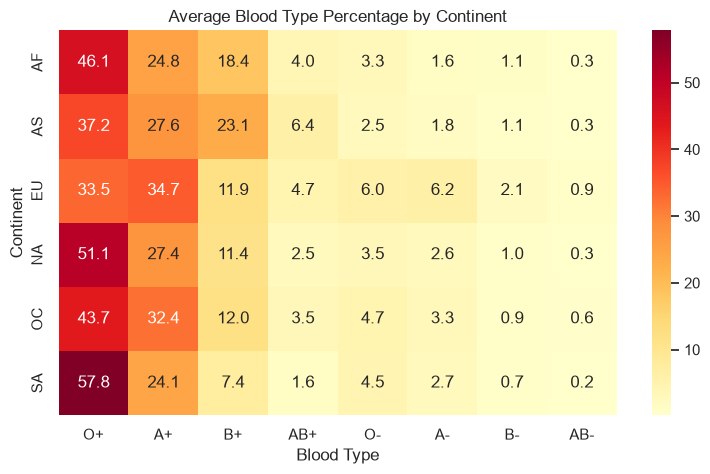

In [50]:
plt.figure(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd')
plt.title('Average Blood Type Percentage by Continent')
plt.xlabel('Blood Type')
plt.ylabel('Continent')
plt.show()